# EDS simulation: induced current, FFT and time-averaged potential energy

Companion notebook to Section 4.2 of the report: the induced current in a figure-8 guideway coil as the train passes, its frequency spectrum, and the time-averaged lateral potential energy.

In [53]:
import numpy as np
from scipy.integrate import dblquad
from scipy.integrate import quad
import matplotlib.pyplot as plt
from scipy.integrate import dblquad
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import jax.numpy as jnp
from jax import grad

Constructing the entire B-field with a four-dipole distribution on the profile. 

## B-field

In [54]:
#Parameters
freq = 200 #Hz
I_0 = 100 #Ampere
mu0 = 4 * np.pi * 0.0000001
def y_t(t): return I_0 * np.sin(freq * t)

In [55]:
#The Magnetic moment of the guidance force
def M_guide(I, R):
    y = (- I) * 2 * np.pi * (R ** 2)
    return np.array([0, y, 0])

def r_distance(r, r_guide):
    (X0, Y0, Z0) = r
    (x, y, z) = r_guide
    #Takes the input of the position of the magnetic dipole. 
    return np.sqrt((X0 - x)**2 + (Y0 - y)**2 + (Z0 - z)**2)

In [56]:
def B_terms(r1, r_guide):
    return 0
    
def B_field(r, r_guide, I = 100, R = 3):
    # Vector field B
    r = r1 - r_guide
    M = M_guide(I, R)
    
    rdotm = np.sum(r * M, axis=-1)
    # Term 1: 3 * r * (r ⋅ m)
    term1 = 3 * r * rdotm[..., np.newaxis]  # shape: (Nx, Ny, Nz, 3)
    # Term 2: m * |r|^2 (broadcasted)
    term2 = m * r_mag2[..., np.newaxis]  # shape: (Nx, Ny, Nz, 3)

    # B-field vector
    prefactor = mu0 / (4 * np.pi)
    B = prefactor * (term1 - term2) / r_mag5[..., np.newaxis]
    
    # Bx, By, Bz components
    Bx, By, Bz = B[..., 0], B[..., 1], B[..., 2]
    return np.array([Bx, By, Bz])

# The Energy

In [70]:
# Parameters of the actual nature.
mu0 = 4 * np.pi * 1e-7
Res = 10

I = 700000
R_g = 1
R_c = 1.5 #Train coils I believe...
A_g = 3.14 * (R_g)**2
n = 2  #Number of guide coils that the train sees


M = (R_c**2) * np.pi * I

L = 1.2
z_0 = 0.7 #The closer to the center, the better it is. 
x_vt = 160 # assume x(vt) = 0 for plotting

x_h_positions = [(2 * h - 1) * R_c for h in range(1, 5)]  # Train coil x-positions

## Flux in time

In [72]:
#We are looking for a description of the current on one guidecoil through time. 
"""
We are interested in what the guideway coil sees as the train passes through it. 
    - Fix the guideway's 8-coil center at x = 0, z_up = + R_g, y = L/2
    - And, we want the format of the flux through time.
    - We want to establish the flux through time of the guidecoil, then differentiate it.
    [2 graphs produced]
"""
def r_train(h, t, y_train):
    #The idea is that each of the train's coil's position can be parameterized with only h and t. 
    output = []
    output.append(x_vt*t + 2 * (h-1) * R_c)
    #print(x_vt*t + 2 * (h-1) * R_c)
    output.append(y_train) #This is not a constant!!! Defined per function...
    output.append(z_0)
    #returns the x, y, z of the train. 
    return output

def r_squared_func(xg, yg, zg, h, t, y):
    #A helper function that computes for every train coil's distance to a specific guide coil at position x, y, z
    [xt, yt, zt] = r_train(h, t, y) #! the t is not fixed
    return (xg - xt)**2 + (yg - yt)**2 + (zg - zt)**2
    
def flux(x, y, z, t, lr, y_train = 0):
    #Flux centered at a certain position x, y, z for the center of the coil.
    #Therefore, the position of the train is determined already and is ran through system.
    total = 0
    for h in range(1, 5):  # h = 1 to 4
        sign = (-1)**h
        r_squared = r_squared_func(x, y, z, h, t, y_train)
        r_five = r_squared ** (2.5)
        numerator = 3 * (y_train - (-1)**lr * L/2)**2 - r_squared
        term = (mu0 * sign * M * R_g**2 / 4) * (numerator / r_five)
        total += term
    #print(total)
    return total

def eight_coil_flux(xg, yg, zg, t, lr, y_train = 0):
    return flux(xg, yg,  R_g, t, y_train, lr) + flux(xg, yg, 0 - R_g, t, y_train, lr)

def emf(x, y, z, t, lr, y_train = 0):
    h = 1e-5
    return (eight_coil_flux(x, y, z, t + h, y_train, lr) - eight_coil_flux(x, y, z, t - h, y_train, lr)) / (2 * h)

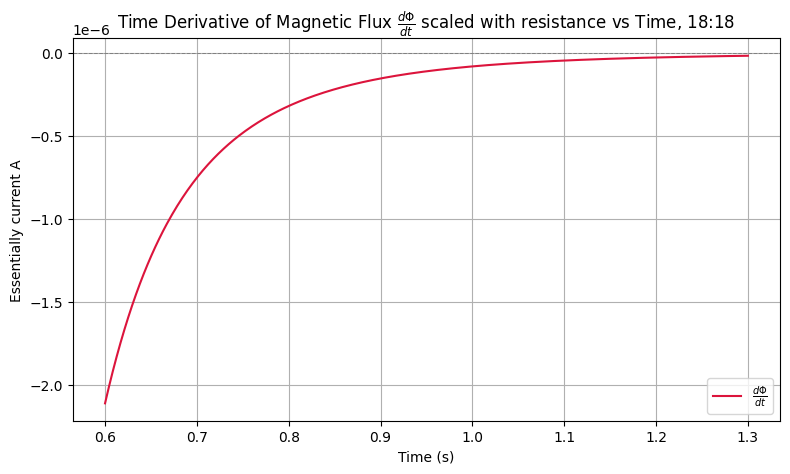

In [73]:
# Time values
t_vals = np.linspace(0.6, 1.3, 500)
    
x_coil = 30

lr = 1
dflux_vals = np.array([emf(x_coil, L/2, R_g, t, lr = 1) for t in t_vals])
dflux_vals = (1/Res) * dflux_vals

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(t_vals, dflux_vals, label=r'$\frac{d\Phi}{dt}$', color='crimson')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.7)
plt.title(r'Time Derivative of Magnetic Flux $\frac{d\Phi}{dt}$ scaled with resistance vs Time, 18:18')
plt.xlabel('Time (s)')
plt.ylabel(r'Essentially current A')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#plot through time

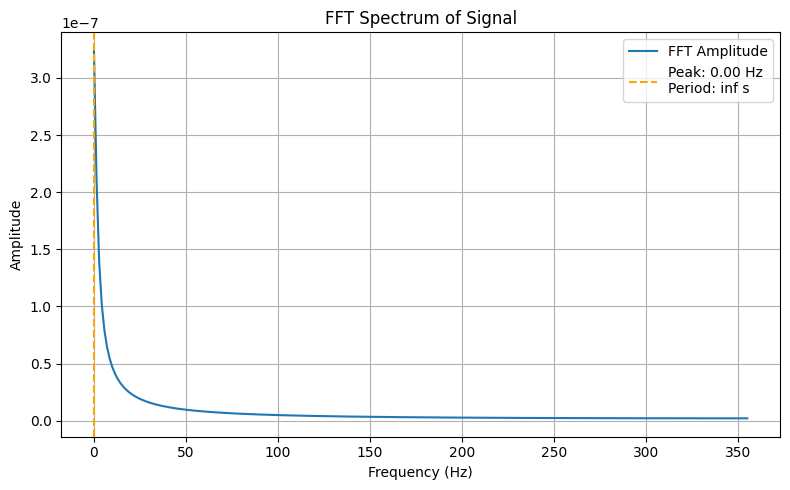

Peak frequency: 0.00 Hz → Period: inf s


In [74]:
def compute_fft(signal, t_vals):
    """
    Computes the FFT of a signal and returns frequency and amplitude spectrum.
    """
    n = len(signal)
    dt = float(t_vals[1] - t_vals[0])  # time step
    freqs = jnp.fft.fftfreq(n, d=dt)   # frequency bins
    fft_vals = jnp.fft.fft(signal)     # complex FFT values
    amplitude = jnp.abs(fft_vals) / n  # normalize amplitude

    # Only keep the positive half of the spectrum
    half_n = n // 2
    return freqs[:half_n], amplitude[:half_n]

# --- Compute and Plot FFT ---
freqs, amp = compute_fft(dflux_vals, t_vals)

peak_idx = jnp.argmax(amp)         # Index of the max amplitude
peak_freq = float(freqs[peak_idx]) # Frequency at that index
period = 1 / peak_freq if peak_freq != 0 else float('inf')

plt.figure(figsize=(8, 5))
plt.plot(freqs, amp, label='FFT Amplitude')
plt.axvline(peak_freq, color='orange', linestyle='--', label=f'Peak: {peak_freq:.2f} Hz\nPeriod: {period:.3f} s')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT Spectrum of Signal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peak frequency: {peak_freq:.2f} Hz → Period: {period:.4f} s")


## Energy with time-average

In [75]:
#The current and the other thing that is useful is the emf function given from above. There will be the same current through the entire 8-coil.
#From this 8-coil current, we expect to see an essentially equal field on all parts.
#This part will intergrate and vary the position y of the train aforedefined whithin the functions. Currently, only the flux has such a dependence.

def current(y_train, lr, x_coil, t):
    # Computes induced current in a guideway 8-coil loop at time 
    y_loop = ((-1)**lr) * (L / 2)
    phi_dot = emf(x_coil, y_loop, R_g, t, lr, y_train)  
    return phi_dot
#The consequence of noting it as such is that we simplifie that there are only two guide coils to consider. 

def B_field(x, y, z, t, y_train, x_coil=30):
    y = y_train
    """
    Computes the y-component of the magnetic field at (x, y, z)
    due to ONE guideway coil at x_coil, side lr, with current induced by train at y_train.

    Parameters:
    - x, y, z: Field evaluation point
    - t: Time (s)
    - y_train: Train's lateral position
    - x_coil: x-position of the guideway coil (default = 0)
    - lr: 1 for right (+L/2), 2 for left (-L/2)

    Returns:
    - B_y: y-component of the magnetic field at (x, y, z) from 1 eight_coil. 
    """
    total_B = 0
    for lr in [1, 2]: #Sum the left and right eight-coils
        y_coil = ((-1)**lr) * (L / 2) #The position of the 8-coil...

        for loop_sign in [+1, -1]: #The up and the down of the eight-coil. 
            z_coil = loop_sign * R_g

            # Compute relative position vector
            dx = x - x_coil
            dy = y - y_coil 
            dz = z - z_coil
            r_vec = np.array([dx, dy, dz])
            r_squared = np.dot(r_vec, r_vec)
    


            r_five = r_squared**5
            r_five = np.sqrt(r_five)

            # Magnetic moment (loop_sign handles top/bottom coil contribution)
            I_loop = current(y_train, lr, x_coil, t) #This SHOULD be the same current for the up and for the down. 
            M = loop_sign * I_loop * np.pi * R_g**2
            M_vec = np.array([0, M, 0])
            M_dot_r = np.dot(M_vec, r_vec)

            # Magnetic field from dipole
            B_vec = (mu0 / (4 * np.pi)) * ((3 * M_dot_r * r_vec - M_vec * r_squared) / r_five)
            total_B += B_vec[1]

    # Return only y-component
    return total_B



def compute_potential(y_train, t, M=M):

    x = 1 #x-Position of the train which is very much wtf
    z = z_0 #height of the train...

    B_y = B_field(x, y_train, z, t, y_train, x_coil=x_coil)

    # Magnetic potential energy: U = -M ⋅ B, with M along y-direction
    U = - M * B_y
    return U

def compute_average_potential(y_train, t_vals):
    U_vals = [compute_potential(y_train, t) for t in t_vals]
    return np.mean(U_vals)


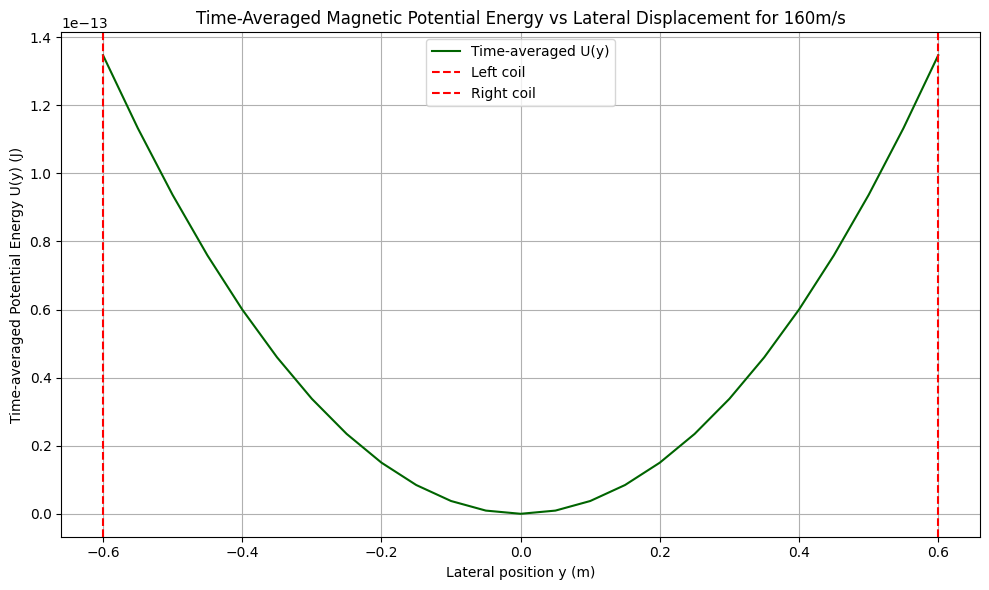

In [76]:
def plot_average_potential_vs_y(y_min=-0.6, y_max=0.6, y_step=0.05, t_start=0, t_end=100, num_t_points=200):
    """
    Plots the time-averaged potential energy of the train as a function of lateral displacement y.
    
    Parameters:
    - y_min, y_max: Range of y positions to evaluate (m)
    - y_step: Step size for y (m)
    - t_start, t_end: Time interval for averaging (s)
    - num_t_points: Number of time samples
    """
    

    y_vals = np.arange(y_min, y_max + y_step, y_step)
    t_vals = np.linspace(t_start, t_end, num_t_points)

    U_avg_vals = [compute_average_potential(y, t_vals) for y in y_vals]
    U_avg_vals = np.array(U_avg_vals)
    U_avg_vals -= U_avg_vals.min()  # shift so minimum is at zero

    plt.figure(figsize=(10, 6))
    plt.plot(y_vals, U_avg_vals, color='darkgreen', label='Time-averaged U(y)')
    plt.xlabel('Lateral position y (m)')
    plt.ylabel('Time-averaged Potential Energy U(y) (J)')

    plt.axvline(x=-L/2, color='red', linestyle='--', label=r'Left coil')
    plt.axvline(x= L/2, color='red', linestyle='--', label=r'Right coil')
    
    plt.title('Time-Averaged Magnetic Potential Energy vs Lateral Displacement for 160m/s')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_average_potential_vs_y()